# 05 — Final USD/LKR Exchange-Rate Forecast

This notebook creates a dated, one-step-ahead forecast using the model selected from validation in Notebook 4. It uses all available historical observations to refit the selected model. The forecast date is intentionally described as the **next observed exchange-rate date**, because the dataset does not establish when CBSL will publish the next observation. A prediction interval is estimated from validation-period forecast errors when available.

## 1. Imports and load saved model-selection metadata

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from xgboost import XGBRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

DATA_PATH = Path("../data/processed/feature_engineered_dataset.csv")
MASTER_PATH = Path("../data/processed/master_dataset.csv")
META_PATH = Path("../data/processed/forecast_metadata.json")
OUT_PATH = Path("../data/processed/final_forecast.csv")
for p in [DATA_PATH, MASTER_PATH, META_PATH]:
    if not p.exists(): raise FileNotFoundError(f"Missing {p}. Run Notebooks 1, 3, and 4 first.")
features_df = pd.read_csv(DATA_PATH, parse_dates=["date", "Target_Date_1", "Target_Date_5", "Target_Date_20"])
master = pd.read_csv(MASTER_PATH, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
metadata = json.loads(META_PATH.read_text(encoding="utf-8"))
print("Selected by validation:", metadata["selected_point_forecast_model_by_validation"])
print("Latest available date:", master["date"].max().date())

Selected by validation: ARIMA
Latest available date: 2026-09-25


## 2. Define the feature set and latest observation

In [2]:
FEATURES = [
    "USD_LKR", "log_return", "days_since_previous_obs", "long_previous_gap",
    "Lag_1", "Lag_5", "Lag_20", "Return_Lag_1", "Return_Lag_5", "Return_Lag_20",
    "Rolling_Mean_5", "Rolling_Mean_20", "Rolling_Std_20", "rolling_volatility_20"
]
latest = features_df.sort_values("date").iloc[-1]
latest_date = pd.Timestamp(latest["date"])
latest_rate = float(latest["USD_LKR"])
print("Latest observation date:", latest_date.date())
print("Latest observed USD/LKR rate:", latest_rate)
print("Forecast horizon: next observed exchange-rate observation")

Latest observation date: 2026-09-25
Latest observed USD/LKR rate: 330.3522
Forecast horizon: next observed exchange-rate observation


## 3. Refit the selected model and forecast one step ahead

The selected model is determined by validation MAE in Notebook 4, not by choosing whichever model looks best after inspecting the test period. ARIMA is refitted to the complete level series. XGBoost is refitted to all historical one-step return targets available before the latest observation.

In [3]:
selected = metadata["selected_point_forecast_model_by_validation"]
if selected == "Naive":
    forecast_rate = latest_rate
    selected_model_name = "Naive baseline"
    # Use validation-period one-step Naive residual quantiles for an empirical interval.
    valid = features_df.dropna(subset=FEATURES + ["Target_1", "Target_Return_1"]).copy()
    valid = valid.loc[(valid["date"] >= pd.Timestamp("2014-01-01")) &
                      ((valid["Target_Date_1"] - valid["date"]).dt.days.between(1,5))]
    n = len(valid); tr_end = int(n * .70); va_end = int(n * .85)
    val_part = valid.iloc[tr_end:va_end]
    val_errors = val_part["Target_1"].to_numpy() - val_part["USD_LKR"].to_numpy()
    q_low, q_high = np.quantile(val_errors, [0.025, 0.975])
    lower, upper = forecast_rate + float(q_low), forecast_rate + float(q_high)
    selected = "Naive"
elif selected == "ARIMA":
    order = tuple(metadata["best_arima_order"])
    history = master.loc[master["date"] >= pd.Timestamp("2014-01-01"), "USD_LKR"].astype(float)
    fitted = ARIMA(history, order=order, enforce_stationarity=False, enforce_invertibility=False).fit()
    forecast_rate = float(np.asarray(fitted.forecast(steps=1))[0])
    selected_model_name = f"ARIMA{order}"
    # Approximate 95% model interval from the ARIMA forecast distribution.
    forecast_obj = fitted.get_forecast(steps=1)
    ci = np.asarray(forecast_obj.conf_int(alpha=0.05))[0]
    lower, upper = float(ci[0]), float(ci[1])
elif selected == "MLP-return":
    cfg = metadata["best_mlp_config"]
    hidden_sizes = tuple(cfg["hidden_layer_sizes"])
    train_data = features_df.dropna(subset=FEATURES + ["Target_Return_1"]).copy()
    train_data = train_data.loc[(train_data["date"] >= pd.Timestamp("2014-01-01")) &
                                ((train_data["Target_Date_1"] - train_data["date"]).dt.days.between(1,5))]
    model = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=hidden_sizes,
            alpha=float(cfg["alpha"]),
            max_iter=500,
            random_state=int(metadata.get("seed", 42))
        )
    )
    model.fit(train_data[FEATURES], train_data["Target_Return_1"])
    predicted_return = float(model.predict(features_df.tail(1)[FEATURES])[0])
    forecast_rate = latest_rate * float(np.exp(predicted_return))
    selected_model_name = "MLPRegressor-return"
    valid = features_df.dropna(subset=FEATURES + ["Target_Return_1", "Target_1"]).copy()
    valid = valid.loc[(valid["date"] >= pd.Timestamp("2014-01-01")) &
                      ((valid["Target_Date_1"] - valid["date"]).dt.days.between(1,5))]
    n = len(valid); tr_end = int(n * .70); va_end = int(n * .85)
    train_part, val_part = valid.iloc[:tr_end], valid.iloc[tr_end:va_end]
    val_model = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=hidden_sizes,
            alpha=float(cfg["alpha"]),
            max_iter=500,
            random_state=int(metadata.get("seed", 42))
        )
    )
    val_model.fit(train_part[FEATURES], train_part["Target_Return_1"])
    val_pred = val_part["USD_LKR"].to_numpy() * np.exp(val_model.predict(val_part[FEATURES]))
    val_errors = val_part["Target_1"].to_numpy() - val_pred
    q_low, q_high = np.quantile(val_errors, [0.025, 0.975])
    lower, upper = forecast_rate + float(q_low), forecast_rate + float(q_high)
else:
    cfg = metadata["best_xgb_config"]
    train_data = features_df.dropna(subset=FEATURES + ["Target_Return_1"]).copy()
    train_data = train_data.loc[(train_data["date"] >= pd.Timestamp("2014-01-01")) &
                                ((train_data["Target_Date_1"] - train_data["date"]).dt.days.between(1,5))]
    model = XGBRegressor(objective="reg:squarederror", random_state=int(metadata.get("seed", 42)), n_jobs=1, **cfg)
    model.fit(train_data[FEATURES], train_data["Target_Return_1"])
    predicted_return = float(model.predict(features_df.tail(1)[FEATURES])[0])
    forecast_rate = latest_rate * float(np.exp(predicted_return))
    selected_model_name = "XGBoost-return"
    # Empirical 95% interval based on validation-period rate-level errors, using same saved config.
    valid = features_df.dropna(subset=FEATURES + ["Target_Return_1", "Target_1"]).copy()
    valid = valid.loc[(valid["date"] >= pd.Timestamp("2014-01-01")) &
                      ((valid["Target_Date_1"] - valid["date"]).dt.days.between(1,5))]
    n = len(valid); tr_end = int(n * .70); va_end = int(n * .85)
    train_part, val_part = valid.iloc[:tr_end], valid.iloc[tr_end:va_end]
    val_model = XGBRegressor(objective="reg:squarederror", random_state=int(metadata.get("seed", 42)), n_jobs=1, **cfg)
    val_model.fit(train_part[FEATURES], train_part["Target_Return_1"])
    val_pred = val_part["USD_LKR"].to_numpy() * np.exp(val_model.predict(val_part[FEATURES]))
    val_errors = val_part["Target_1"].to_numpy() - val_pred
    q_low, q_high = np.quantile(val_errors, [0.025, 0.975])
    lower, upper = forecast_rate + float(q_low), forecast_rate + float(q_high)

print("Selected model:", selected_model_name)
print("Forecast USD/LKR:", round(forecast_rate, 4))
print("Approximate 95% prediction interval:", round(lower, 4), "to", round(upper, 4))

Selected model: ARIMA(1, 1, 1)
Forecast USD/LKR: 330.3869
Approximate 95% prediction interval: 327.8478 to 332.926


## 4. Create and save the forecast record

The next observation date is left blank because it is not known from the historical dataset. The record states the latest data date, the forecast horizon, the model used, the forecast, and the approximate interval.

In [4]:
forecast_result = pd.DataFrame([{
    "Latest_Observation_Date": latest_date.date().isoformat(),
    "Forecast_Date": "Next observed date (not yet known)",
    "Forecast_Horizon": "One-step-ahead / next observed observation",
    "Selected_Model": selected_model_name,
    "Latest_Observed_USD_LKR": latest_rate,
    "Forecast_USD_LKR": forecast_rate,
    "Approx_95PI_Lower": lower,
    "Approx_95PI_Upper": upper,
    "Interval_Method": "ARIMA model interval" if selected == "ARIMA" else "Empirical validation residual quantiles",
}])
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
forecast_result.to_csv(OUT_PATH, index=False)
print("Saved forecast to:", OUT_PATH)
forecast_result

Saved forecast to: ..\data\processed\final_forecast.csv


,Latest_Observation_Date,Forecast_Date,Forecast_Horizon,Selected_Model,Latest_Observed_USD_LKR,Forecast_USD_LKR,Approx_95PI_Lower,Approx_95PI_Upper,Interval_Method
0,2026-09-25,Next observed date (not yet known),One-step-ahead / next observed observation,"ARIMA(1, 1, 1)",330.3522,330.386922,327.847849,332.925995,ARIMA model interval


## 5. Plot recent observations and forecast interval

The forecast is plotted at a labelled placeholder point after the latest observation. The x-axis label is categorical because the actual next observation date is not known yet.

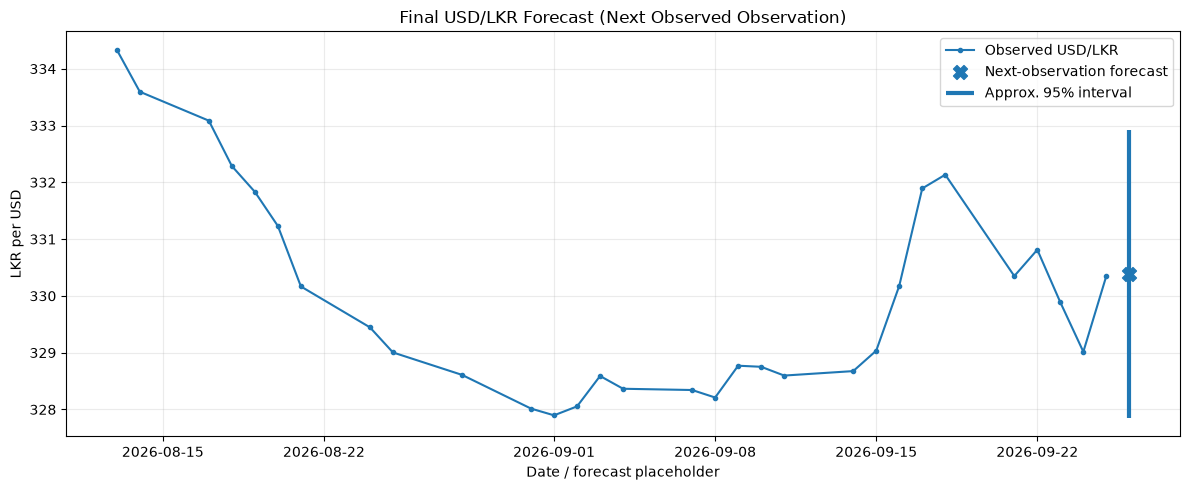

In [5]:
recent = master.tail(30).copy()
plt.figure(figsize=(12, 5))
plt.plot(recent["date"], recent["USD_LKR"], marker="o", markersize=3, label="Observed USD/LKR")
forecast_x = latest_date + pd.Timedelta(days=1)
plt.scatter([forecast_x], [forecast_rate], marker="X", s=100, label="Next-observation forecast")
plt.vlines(forecast_x, lower, upper, linewidth=3, label="Approx. 95% interval")
plt.title("Final USD/LKR Forecast (Next Observed Observation)")
plt.xlabel("Date / forecast placeholder")
plt.ylabel("LKR per USD")
plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

## 6. Conclusion and limitations

The forecast uses the model selected by validation performance and refits it using the available historical data. The forecast date is the next observed exchange-rate date, not a guaranteed calendar date. Prediction intervals are approximate and depend on model assumptions or the stability of validation-period errors. Exchange-rate policy changes, liquidity conditions, and unexpected economic events can cause actual values to fall outside the interval. This forecast should be interpreted as a statistical estimate, not a financial recommendation.